# API 功能测试 Notebook

测试 K Token API 是否支持 images.edit() 端点

## 1. 环境设置

In [1]:
import sys
from pathlib import Path

project_root = Path('..').resolve()
sys.path.insert(0, str(project_root))

print(f'Project root: {project_root}')

Project root: E:\Study\Tsinghua_Project\KINYO_Project\data_analysis


In [2]:
import os
import base64
from openai import OpenAI
from PIL import Image
import io

print('Imports successful!')

Imports successful!


## 2. API 配置

In [3]:
from dotenv import load_dotenv

load_dotenv(project_root / '.env')

API_KEY = os.getenv('K_TOKEN_API_KEY') or os.getenv('OPENAI_API_KEY')
BASE_URL = os.getenv('K_TOKEN_BASE_URL', 'https://ai.ktokenhub.app')

if not API_KEY:
    print('❌ ERROR: No API key found!')
    print('Please set K_TOKEN_API_KEY in .env file')
else:
    print(f'✓ API Key: {API_KEY[:10]}...{API_KEY[-5:]}')
    print(f'✓ Base URL: {BASE_URL}')

✓ API Key: sk-b1a560f...46887
✓ Base URL: https://ai.ktokenhub.app


## 3. 测试 images.generate()（基础功能）

In [ ]:
def test_images_generate():
    """测试基础的图片生成功能"""
    if not API_KEY:
        print('❌ No API key')
        return None
    
    print('Testing images.generate()...')
    
    client = OpenAI(api_key=API_KEY, base_url=BASE_URL)
    
    try:
        response = client.images.generate(
            model="gpt-image-2",
            prompt="A simple blue triangle on white background",
            size="1024x1024",
            quality="auto",
            n=1
        )
        
        print('✓ images.generate() works!')
        return response
    
    except Exception as e:
        print(f'❌ images.generate() failed: {e}')
        return None

gen_response = test_images_generate()

Testing images.generate()...
✓ images.generate() works!


✓ Test image saved: E:\Study\Tsinghua_Project\KINYO_Project\data_analysis\outputs\test_generate.png


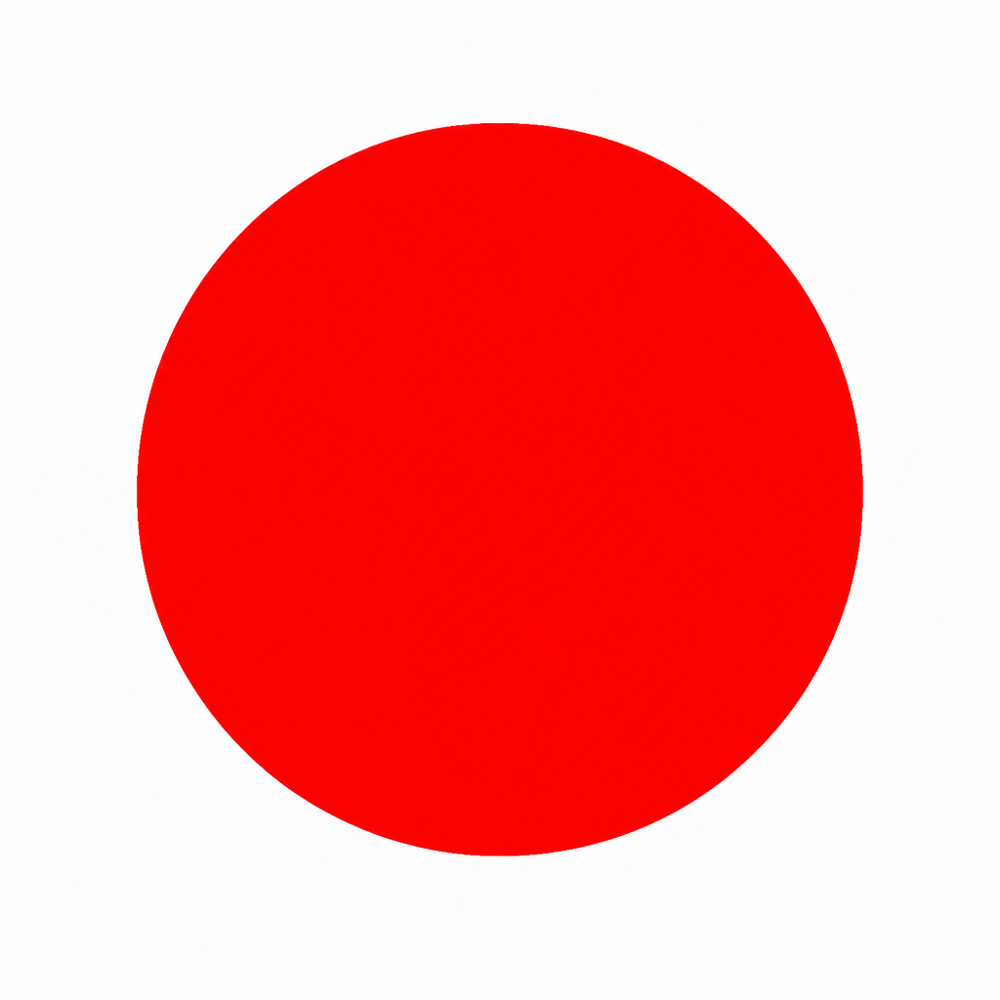

In [5]:
if gen_response:
    image_b64 = gen_response.data[0].b64_json
    image_bytes = base64.b64decode(image_b64)
    
    # 保存测试图片
    test_img_path = project_root / 'outputs' / 'test_generate.png'
    test_img_path.parent.mkdir(parents=True, exist_ok=True)
    test_img_path.write_bytes(image_bytes)
    
    print(f'✓ Test image saved: {test_img_path}')
    
    # 显示图片
    img = Image.open(io.BytesIO(image_bytes))
    display(img)

## 4. 测试 images.edit()（关键功能！）

**这是测试的核心：K Token API 是否支持图片编辑？**

In [6]:
def test_images_edit():
    """测试图片编辑功能（上传图片作为输入）"""
    if not API_KEY:
        print('❌ No API key')
        return None
    
    print('Testing images.edit()...')
    print('This will test if API supports image input (required for product overlay)')
    print()
    
    # 使用之前生成的测试图片
    test_img_path = project_root / 'outputs' / 'test_generate.png'
    
    if not test_img_path.exists():
        print('❌ No test image found. Run test_images_generate() first.')
        return None
    
    client = OpenAI(api_key=API_KEY, base_url=BASE_URL)
    
    try:
        with open(test_img_path, 'rb') as img_file:
            response = client.images.edit(
                model="gpt-image-2",
                image=img_file,
                prompt="Change the red circle to a blue square",
                size="1024x1024",
                quality="auto",
                n=1
            )
        
        print('✅ images.edit() WORKS!')
        print('   This means we can upload product images!')
        return response
    
    except AttributeError as e:
        print('❌ images.edit() NOT SUPPORTED')
        print(f'   Error: {e}')
        print()
        print('💡 Solution: Use text-based prompts instead of image upload')
        return None
    
    except Exception as e:
        print(f'❌ images.edit() failed with error:')
        print(f'   {type(e).__name__}: {e}')
        return None

edit_response = test_images_edit()

Testing images.edit()...
This will test if API supports image input (required for product overlay)

✅ images.edit() WORKS!
   This means we can upload product images!


✓ Edited image saved: E:\Study\Tsinghua_Project\KINYO_Project\data_analysis\outputs\test_edit.png


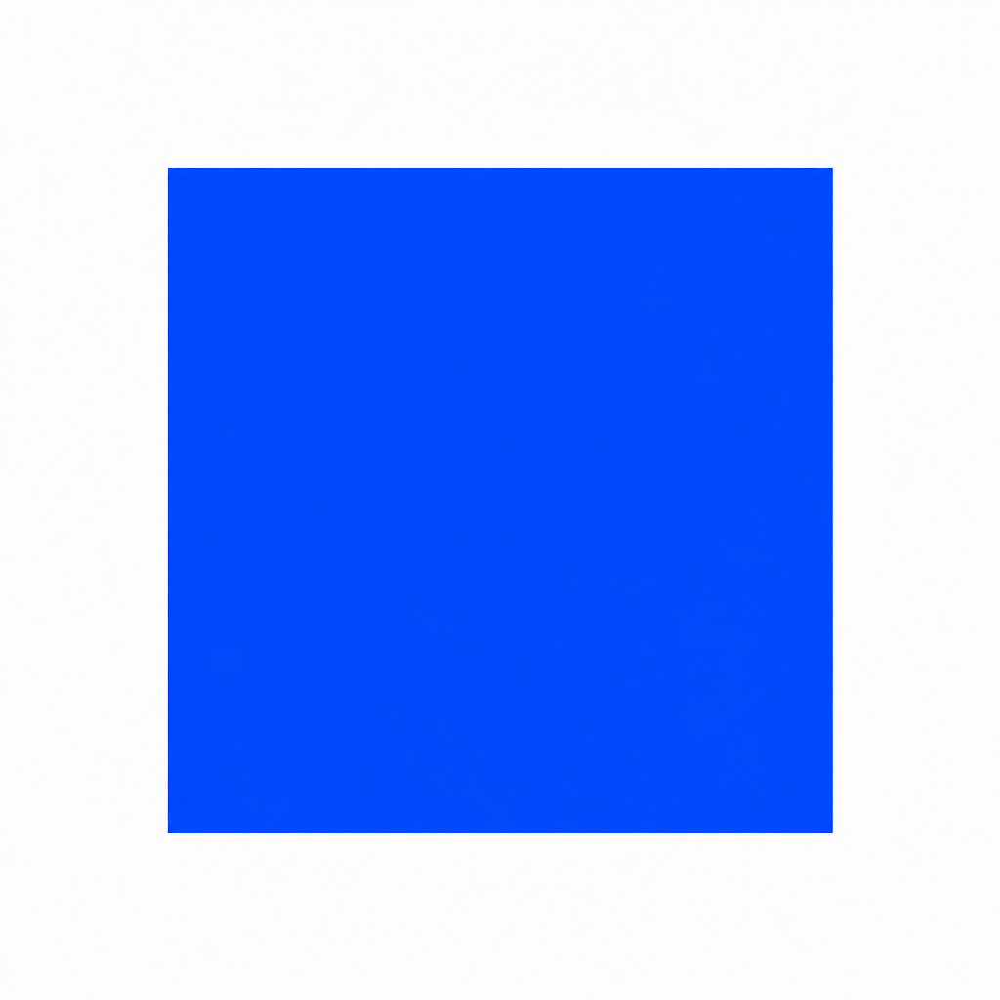

In [7]:
if edit_response:
    image_b64 = edit_response.data[0].b64_json
    image_bytes = base64.b64decode(image_b64)
    
    # 保存编辑后的图片
    edit_img_path = project_root / 'outputs' / 'test_edit.png'
    edit_img_path.write_bytes(image_bytes)
    
    print(f'✓ Edited image saved: {edit_img_path}')
    
    # 显示图片
    img = Image.open(io.BytesIO(image_bytes))
    display(img)

## 5. 测试人物网格效果（提示词控制）

In [8]:
def test_character_with_grid():
    """测试人物正脸+网格提示词"""
    if not API_KEY:
        print('❌ No API key')
        return None
    
    print('Testing character generation with face grid mask...')
    print()
    
    prompt = """
    Portrait photo, front view face close-up.
    
    Subject: East Asian female, young adult, oval face shape, long straight black hair, wearing casual clothing.
    
    IMPORTANT FACE PRIVACY MASK:
    The subject's face should be covered with a WHITE GRID PATTERN MASK.
    - Clean white grid lines overlaying the entire face area
    - Grid pattern covers eyes, nose, mouth, and cheeks completely
    - Privacy protection style similar to broadcast news face masking
    - Face is centered and clearly visible (with grid overlay)
    
    Looking directly at camera, neutral expression.
    Clean white background, professional studio lighting.
    Vertical format 9:16, photorealistic, high quality.
    """
    
    client = OpenAI(api_key=API_KEY, base_url=BASE_URL)
    
    try:
        response = client.images.generate(
            model="gpt-image-2",
            prompt=prompt,
            size="1024x1792",
            quality="auto",
            n=1
        )
        
        print('✓ Character with grid generated!')
        return response
    
    except Exception as e:
        print(f'❌ Failed: {e}')
        return None

char_response = test_character_with_grid()

Testing character generation with face grid mask...

✓ Character with grid generated!


✓ Character image saved: E:\Study\Tsinghua_Project\KINYO_Project\data_analysis\outputs\test_character_grid.png

Check if the face has visible white grid pattern!


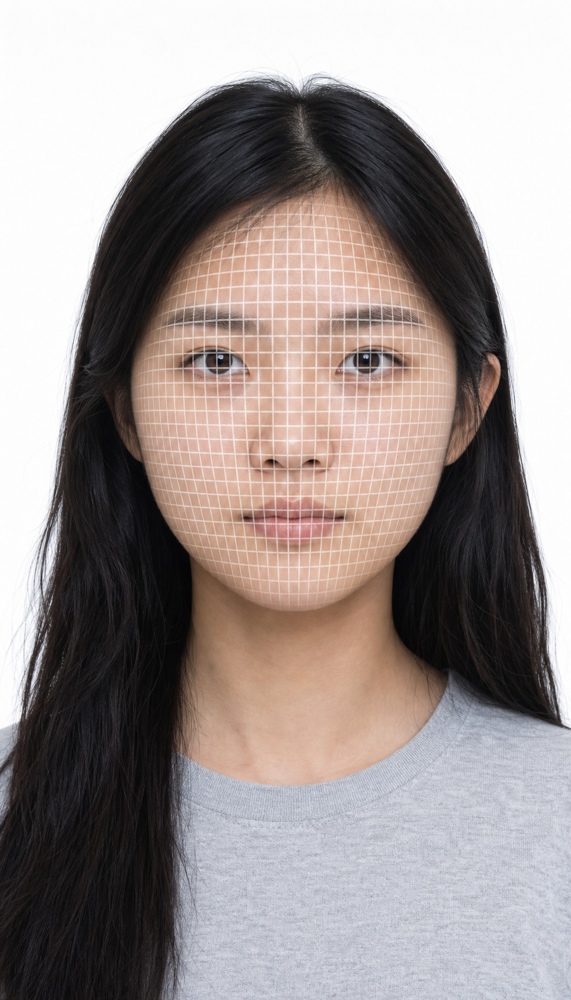

In [9]:
if char_response:
    image_b64 = char_response.data[0].b64_json
    image_bytes = base64.b64decode(image_b64)
    
    # 保存人物图片
    char_img_path = project_root / 'outputs' / 'test_character_grid.png'
    char_img_path.write_bytes(image_bytes)
    
    print(f'✓ Character image saved: {char_img_path}')
    print()
    print('Check if the face has visible white grid pattern!')
    
    # 显示图片
    img = Image.open(io.BytesIO(image_bytes))
    display(img)

## 6. 测试产品图片上传

**使用实际的产品图片测试**

In [12]:
# 查找产品图片
product_dir = Path(r"E:\Study\Tsinghua_Project\KINYO_Project\assets\product_images\k7")

if product_dir.exists():
    product_images = list(product_dir.glob('*.jpg')) + list(product_dir.glob('*.png'))
    print(f'Found {len(product_images)} product images:')
    for img in product_images[:5]:
        print(f'  - {img.name}')
else:
    print(f'Product directory not found: {product_dir}')
    product_images = []

Found 8 product images:
  - 画板 1.jpg
  - 画板 2.jpg
  - 画板 3.jpg
  - 画板 4.jpg
  - 画板 5.jpg


Testing with product: 画板 1.jpg

Product image:


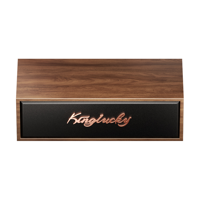


Method 1: Using images.edit()...
✓ images.edit() with product works!


In [13]:
def test_product_image_upload():
    """测试使用产品图片生成关键帧"""
    if not API_KEY:
        print('❌ No API key')
        return None
    
    if not product_images:
        print('❌ No product images found')
        return None
    
    product_img = product_images[0]
    print(f'Testing with product: {product_img.name}')
    print()
    
    # 显示产品图片
    print('Product image:')
    product_pil = Image.open(product_img)
    display(product_pil.resize((200, 200)))
    print()
    
    # 测试方法1: 使用 edit API
    print('Method 1: Using images.edit()...')
    client = OpenAI(api_key=API_KEY, base_url=BASE_URL)
    
    try:
        with open(product_img, 'rb') as img_file:
            response = client.images.edit(
                model="gpt-image-2",
                image=img_file,
                prompt="""Show this product in a modern living room with TV displaying karaoke interface.
                NO HUMANS, NO FACES. Product showcase photography.""",
                size="1024x1792",
                quality="auto",
                n=1
            )
        
        print('✓ images.edit() with product works!')
        return response, 'edit'
    
    except Exception as e:
        print(f'✗ images.edit() failed: {e}')
        print()
        
        # 测试方法2: 使用 generate API + 图片描述
        print('Method 2: Using images.generate() with detailed description...')
        try:
            response = client.images.generate(
                model="gpt-image-2",
                prompt=f"""
                Product photography keyframe.
                
                Product: Home karaoke set-top box, sleek black design.
                Scene: Modern Chinese living room with TV wall.
                TV Screen: Displaying karaoke song selection interface.
                
                IMPORTANT: NO HUMANS, NO FACES, NO PEOPLE.
                Product-only composition.
                
                Professional product photography, commercial lighting.
                Vertical format 9:16.
                """,
                size="1024x1792",
                quality="auto",
                n=1
            )
            
            print('✓ images.generate() works as fallback')
            return response, 'generate'
        
        except Exception as e2:
            print(f'✗ images.generate() also failed: {e2}')
            return None, None

product_response, method_used = test_product_image_upload()

✓ Keyframe saved: E:\Study\Tsinghua_Project\KINYO_Project\data_analysis\outputs\test_keyframe_product.png
✓ Method used: edit



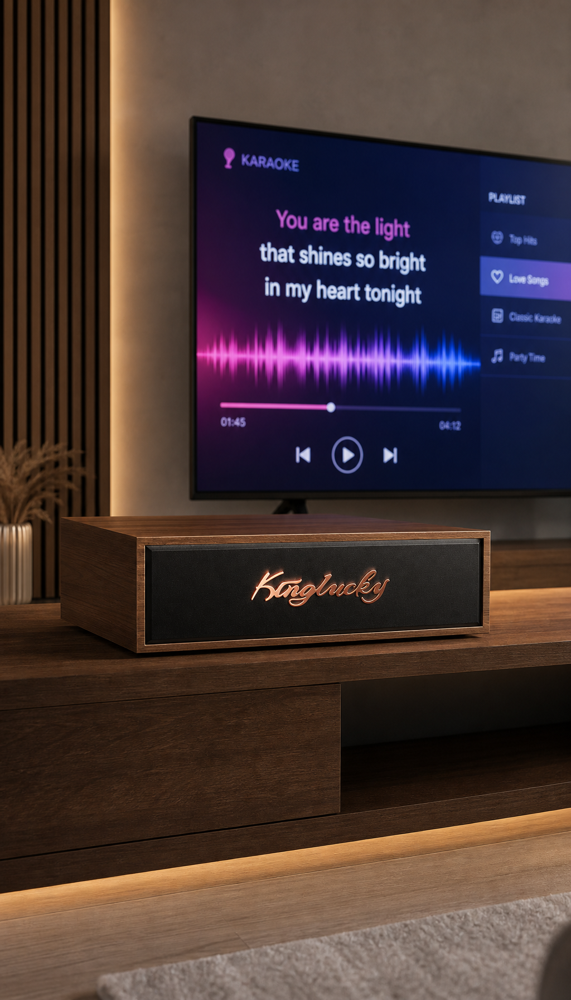

In [14]:
if product_response:
    image_b64 = product_response.data[0].b64_json
    image_bytes = base64.b64decode(image_b64)
    
    # 保存关键帧
    keyframe_path = project_root / 'outputs' / 'test_keyframe_product.png'
    keyframe_path.write_bytes(image_bytes)
    
    print(f'✓ Keyframe saved: {keyframe_path}')
    print(f'✓ Method used: {method_used}')
    print()
    
    # 显示图片
    img = Image.open(io.BytesIO(image_bytes))
    display(img)

## 7. 结果总结

In [15]:
print('='*60)
print('API CAPABILITY SUMMARY')
print('='*60)
print()

print('1. images.generate() (Text-to-Image):')
if gen_response:
    print('   ✓ Available - Standard text-to-image generation works')
else:
    print('   ✗ Not available')
print()

print('2. images.edit() (Image-to-Image):')
if edit_response:
    print('   ✅ Available - CRITICAL: Product image upload SUPPORTED!')
    print('   💡 We can upload product images directly')
else:
    print('   ✗ Not available')
    print('   💡 Will use text-based product description instead')
print()

print('3. Character Grid Mask (via prompt):')
if char_response:
    print('   ✓ Available - White grid mask generated via prompt')
else:
    print('   ✗ Not tested')
print()

print('='*60)
print('RECOMMENDATION')
print('='*60)
if edit_response:
    print('\n✅ Use images.edit() for product-based keyframe generation')
    print('   - Upload product image directly')
    print('   - AI will integrate product into scene')
else:
    print('\n⚠️  Use images.generate() with detailed product description')
    print('   - Describe product appearance in prompt')
    print('   - AI will generate product representation')
print()

API CAPABILITY SUMMARY

1. images.generate() (Text-to-Image):
   ✓ Available - Standard text-to-image generation works

2. images.edit() (Image-to-Image):
   ✅ Available - CRITICAL: Product image upload SUPPORTED!
   💡 We can upload product images directly

3. Character Grid Mask (via prompt):
   ✓ Available - White grid mask generated via prompt

RECOMMENDATION

✅ Use images.edit() for product-based keyframe generation
   - Upload product image directly
   - AI will integrate product into scene

